> **Output-space illustration only.** For the corrected example in which each point represents a complete input–output window, use [input_output_trajectory_surface.ipynb](input_output_trajectory_surface.ipynb). The cylinder and its earlier introduction text do not illustrate full trajectory-window geometry.

# A nonlinear system whose measured trajectories lie on a cylinder

**Purpose.** A small, reproducible motivation example for three questions in the introduction:

1. Which offline trajectories are relevant near the current operating condition?
2. How can observed transitions suggest intermediate references toward a distant goal?
3. Why should a desired future motion influence the selected trajectory group?

The measured output is already in $\mathbb R^3$, and every noise-free sample lies **exactly** on a curved two-dimensional surface. There is no PCA projection or fitted visualization manifold. Local planes approximate this surface; a cylinder is curved circumferentially and flat vertically.

This notebook illustrates geometry and data organization. Its affine regression diagnostic is **not DeePC**, its graph is **not a reachability certificate**, and its reference-conditioned selection is **not a closed-loop performance comparison**. A low-dimensional output surface does not imply that full input-output trajectory windows have the same dimension.

## 1. A controlled nonlinear system with an exact embedding

Let $q_k=(\theta_k,z_k)\in S^1\times\mathbb R$, input $u_k=(\omega_k,v_k)$, sample step $h=0.12$, and $a=0.35$. Define the discrete-time system

$$\theta_{k+1}=\theta_k+h\omega_k,\qquad
z_{k+1}=z_k+h(v_k+a\sin\theta_k),\qquad
y_k=\begin{bmatrix}\cos\theta_k&\sin\theta_k&z_k\end{bmatrix}^{\mathsf T}.$$

Equivalently, the three measured coordinates satisfy the exact update

$$y_{k+1}=\begin{bmatrix}
y_{1,k}\cos(h\omega_k)-y_{2,k}\sin(h\omega_k)\\
y_{1,k}\sin(h\omega_k)+y_{2,k}\cos(h\omega_k)\\
y_{3,k}+h(v_k+a y_{2,k})
\end{bmatrix}.$$

The admissible outputs form the invariant cylinder $\mathcal M=\{y:y_1^2+y_2^2=1\}$. The intrinsic state has two degrees of freedom; its measured embedding has three coordinates. The $\sin\theta$ drift makes the chosen intrinsic dynamics nonlinear, and the measured angular input direction changes around the cylinder. A single fixed affine predictor in $(y,u)$ cannot represent the rotation term exactly. A richer nonlinear feature model could; this example concerns the motivation for **local affine representations**.

This is a deliberately simple discrete-time plant, not a claimed exact discretization of continuous-time vertical drift. Offline inputs obey $|\omega|\leq1.2$ and $|v|\leq0.8$.

In [1]:
from pathlib import Path
import os
import json
import numpy as np

# Works when opened from this folder or the project root.
PROJECT = next(p for p in (Path.cwd(), *Path.cwd().parents)
               if (p / "notebooks").is_dir() and (p / "src").is_dir())
OUT = PROJECT / "notebooks" / "motivation" / "figures"
OUT.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(Path("/tmp") / "atlas_motivation_mpl"))
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra

plt.rcParams.update({"font.size": 10, "axes.titlesize": 12,
                     "figure.dpi": 120, "savefig.dpi": 220,
                     "pdf.fonttype": 42, "ps.fonttype": 42})
SEED, H, A = 17, 0.12, 0.35
COLORS = {"data": "#52677D", "local": "#168B89", "route": "#E09430",
          "plus": "#D75C45", "minus": "#476AC1", "past": "#273444"}

def embed(theta, z):
    theta, z = np.broadcast_arrays(theta, z)
    return np.stack([np.cos(theta), np.sin(theta), z], axis=-1)

def step(y, u):
    y, u = np.asarray(y), np.asarray(u)
    c, s = np.cos(H * u[..., 0]), np.sin(H * u[..., 0])
    return np.stack([c*y[..., 0] - s*y[..., 1],
                     s*y[..., 0] + c*y[..., 1],
                     y[..., 2] + H*(u[..., 1] + A*y[..., 1])], axis=-1)

def collect(seed, n_rollouts=96, length=75):
    rng = np.random.default_rng(seed)
    rollouts = []
    for _ in range(n_rollouts):
        y = embed(rng.uniform(-np.pi, np.pi), rng.uniform(-0.85, 0.85))
        ys, us = [y.copy()], []
        omega, vertical = 0.0, 0.0
        for k in range(length):
            if k % 9 == 0:
                omega = rng.uniform(-1.2, 1.2)
                vertical = rng.uniform(-0.55, 0.55)
            # Bounded exploration policy; the plant still uses the recorded input.
            v = np.clip(vertical - 0.45*y[2] - A*y[1], -0.8, 0.8)
            u = np.array([omega, v])
            y = step(y, u)
            us.append(u); ys.append(y.copy())
        rollouts.append((np.asarray(ys), np.asarray(us)))
    return rollouts

train = collect(SEED)
test = collect(SEED + 1, n_rollouts=32)  # Entirely separate rollouts.
Y = np.concatenate([ys[:-1] for ys, us in train])
U = np.concatenate([us for ys, us in train])
Ynext = np.concatenate([ys[1:] for ys, us in train])
Ytest = np.concatenate([ys[:-1] for ys, us in test])
Utest = np.concatenate([us for ys, us in test])
Ynext_test = np.concatenate([ys[1:] for ys, us in test])
print(f"Offline transitions: {len(Y):,}; held-out transitions: {len(Ytest):,}")

Offline transitions: 7,200; held-out transitions: 2,400


### See the full cylinder surface

The following **additional visualization rollouts** use the same plant and input bounds, with initial angles spread around the cylinder and a slow, constant upward motion. They are designed to reveal the full circumference and the height interval $z\in[-1,1]$; they do not replace the random training or test data used below.

Each colored curve is generated by repeated calls to `step`, not by drawing a helix independently of the dynamics. The gray wireframe is the known invariant surface. The top view shows that all samples have unit radius, while the unwrapped view shows coverage of both surface coordinates. One trajectory is highlighted in orange: **one rollout is a curve; the collection samples a two-dimensional cylindrical surface**. A finite collection of curves does not literally cover every surface point.


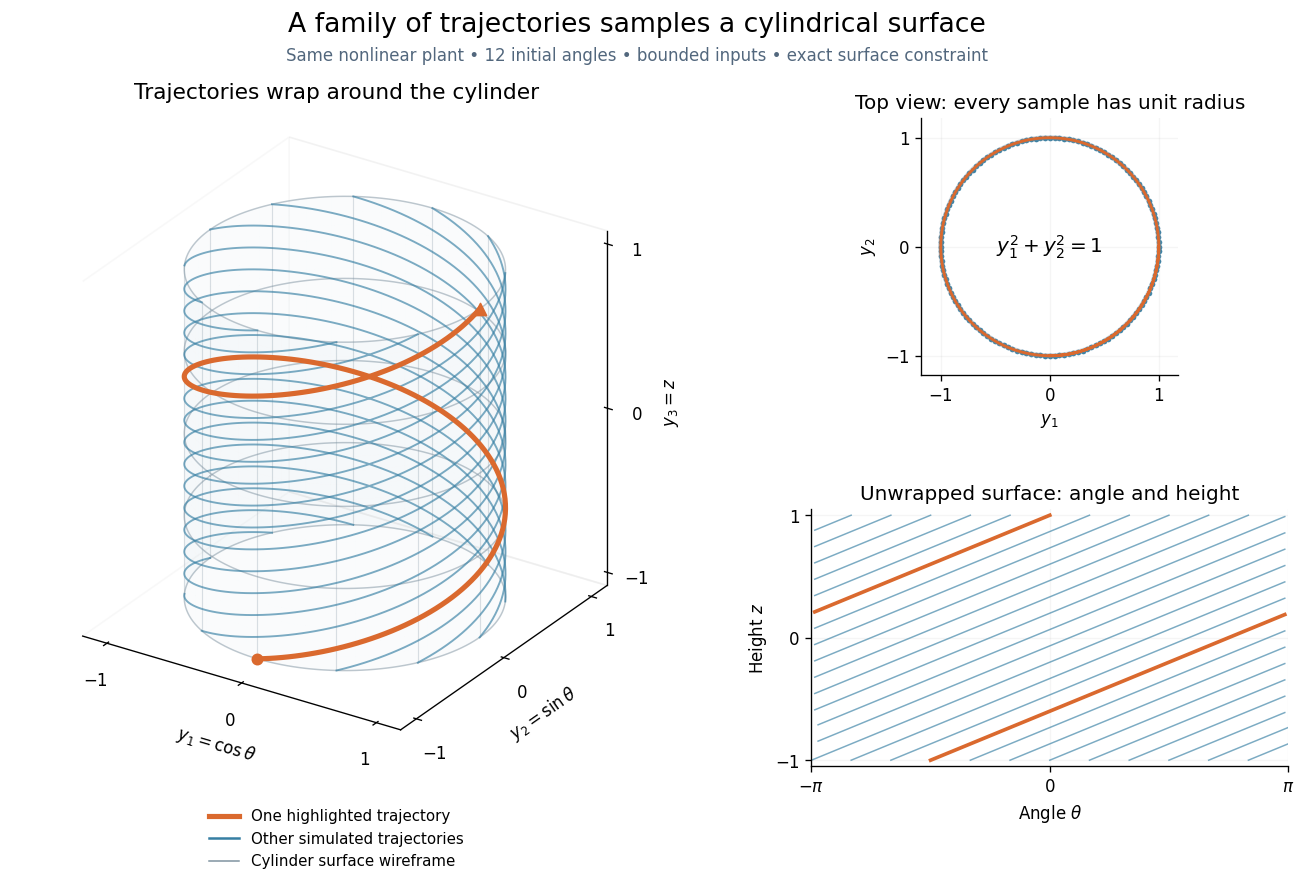

In [2]:
# A controlled sweep exposes the geometry more clearly than short random walks.
N_COVER, COVER_STEPS, TURNS = 12, 180, 1.25
cover_omega = 2*np.pi*TURNS / (COVER_STEPS*H)
cover_vertical = 2.0 / (COVER_STEPS*H)
coverage_rollouts = []
for theta0 in np.linspace(-np.pi, np.pi, N_COVER, endpoint=False):
    ys, us = [embed(theta0, -1.0)], []
    for _ in range(COVER_STEPS):
        u = np.array([cover_omega, cover_vertical - A*ys[-1][1]])
        us.append(u)
        ys.append(step(ys[-1], u))
    coverage_rollouts.append((np.asarray(ys), np.asarray(us)))
coverage = np.concatenate([ys for ys, us in coverage_rollouts])
for ys, us in coverage_rollouts:
    assert np.max(np.abs(np.sum(ys[:, :2]**2, axis=1) - 1)) < 1e-12
    assert np.all(np.abs(us) <= np.array([1.2, 0.8]) + 1e-12)
    assert np.isclose(ys[-1, 2], 1.0)

fig = plt.figure(figsize=(11.8, 7.4))
grid = fig.add_gridspec(2, 2, width_ratios=[1.65, 1],
                        left=0.01, right=0.96, bottom=0.13, top=0.86,
                        wspace=0.13, hspace=0.52)
ax3 = fig.add_subplot(grid[:, 0], projection="3d", computed_zorder=False)
axtop = fig.add_subplot(grid[0, 1])
axflat = fig.add_subplot(grid[1, 1])
angle = np.linspace(-np.pi, np.pi, 160)
aa, zz = np.meshgrid(angle, np.linspace(-1, 1, 24))
ax3.plot_surface(np.cos(aa), np.sin(aa), zz, color="#AFC8D9",
                 alpha=0.055, linewidth=0, shade=False, zorder=0)
# Rings and generators mark the surface, not solid cylinder end caps.
for height in np.linspace(-1, 1, 5):
    ax3.plot(np.cos(angle), np.sin(angle), np.full_like(angle, height),
             color="#7D919F", lw=0.9, alpha=0.5, zorder=1)
for theta in np.linspace(-np.pi, np.pi, 12, endpoint=False):
    ax3.plot([np.cos(theta)]*2, [np.sin(theta)]*2, [-1, 1],
             color="#7D919F", lw=0.7, alpha=0.28, zorder=1)

highlight = 3
for j, (ys, _) in enumerate(coverage_rollouts):
    if j == highlight:
        continue
    ax3.plot(*ys.T, color="#367FA3", lw=1.15, alpha=0.65, zorder=2)
ys = coverage_rollouts[highlight][0]
ax3.plot(*ys.T, color="#DA692E", lw=3.1, zorder=3, label="One highlighted trajectory")
ax3.scatter(*ys[0], color="#DA692E", marker="o", s=38, zorder=4)
ax3.scatter(*ys[-1], color="#DA692E", marker="^", s=52, zorder=4)
ax3.plot([], [], [], color="#367FA3", lw=1.5, label="Other simulated trajectories")
ax3.plot([], [], [], color="#7D919F", lw=0.9, label="Cylinder surface wireframe")
ax3.set(xlim=(-1.18, 1.18), ylim=(-1.18, 1.18), zlim=(-1.08, 1.08),
        xlabel="$y_1 = \\cos\\theta$", ylabel="$y_2 = \\sin\\theta$", zlabel="$y_3 = z$")
ax3.set_xticks([-1, 0, 1]); ax3.set_yticks([-1, 0, 1]); ax3.set_zticks([-1, 0, 1])
ax3.set_box_aspect((1, 1, 1.05))
ax3.view_init(elev=27, azim=-57)
ax3.set_proj_type("ortho")
ax3.grid(False)
for axis in [ax3.xaxis, ax3.yaxis, ax3.zaxis]:
    axis.pane.fill = False
ax3.set_title("Trajectories wrap around the cylinder", pad=12, fontsize=13)
ax3.legend(loc="upper center", bbox_to_anchor=(0.5, -0.045), frameon=False, fontsize=9)

axtop.plot(np.cos(angle), np.sin(angle), color="#7D919F", lw=3, alpha=0.35)
axtop.scatter(coverage[::4, 0], coverage[::4, 1], s=5, color="#367FA3", alpha=0.5)
axtop.plot(ys[:, 0], ys[:, 1], color="#DA692E", lw=1.7)
axtop.text(0, 0, "$y_1^2+y_2^2=1$", ha="center", va="center", fontsize=12)
axtop.set(xlabel="$y_1$", ylabel="$y_2$", xlim=(-1.18, 1.18), ylim=(-1.18, 1.18),
          title="Top view: every sample has unit radius")
axtop.set_aspect("equal", adjustable="box")
axtop.set_xticks([-1, 0, 1]); axtop.set_yticks([-1, 0, 1])
for j, (path, _) in enumerate(coverage_rollouts):
    theta = np.arctan2(path[:, 1], path[:, 0])
    # Break the curve at the display seam instead of connecting across it.
    seam = np.r_[False, np.abs(np.diff(theta)) > np.pi]
    theta = theta.copy(); theta[seam] = np.nan
    axflat.plot(theta, path[:, 2], color="#DA692E" if j == highlight else "#367FA3",
                lw=2.2 if j == highlight else 0.9,
                alpha=1.0 if j == highlight else 0.65,
                zorder=3 if j == highlight else 2)
axflat.set(xlim=(-np.pi, np.pi), ylim=(-1.05, 1.05), xlabel="Angle $\\theta$", ylabel="Height $z$",
           title="Unwrapped surface: angle and height")
axflat.set_xticks([-np.pi, 0, np.pi], ["$-\\pi$", "$0$", "$\\pi$"])
axflat.set_yticks([-1, 0, 1])
for ax in [axtop, axflat]:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.12)
fig.suptitle("A family of trajectories samples a cylindrical surface", fontsize=16, y=0.98)
fig.text(0.5, 0.925, "Same nonlinear plant • 12 initial angles • bounded inputs • exact surface constraint",
         ha="center", color="#52677D", fontsize=10)
for extension in ["png", "pdf"]:
    fig.savefig(OUT / f"cylinder_surface_coverage.{extension}", bbox_inches="tight", pad_inches=0.3)
plt.show()

### Publication figure and introduction text

The standalone figure below reproduces the cylinder panel at a single-column width of 3.5 inches, with Times New Roman labels. Its separate plotting script exports a vector [PDF](figures/cylinder_paper.pdf), [SVG](figures/cylinder_paper.svg), and [600 dpi PNG](figures/cylinder_paper.png). The script uses the same plant and fixed visualization sweep parameters described above; edit `cylinder_paper_figure.py` to change this publication figure.

Ready-to-use [introduction text and caption](cylinder_introduction.md), including the system equations, are also available as a [LaTeX snippet](cylinder_introduction.tex).


Times New Roman: /System/Library/Fonts/Supplemental/Times New Roman.ttf
Publication figure: /Users/kumiko/Projects/atlas_deepc_reacher/notebooks/motivation/figures/cylinder_paper.pdf



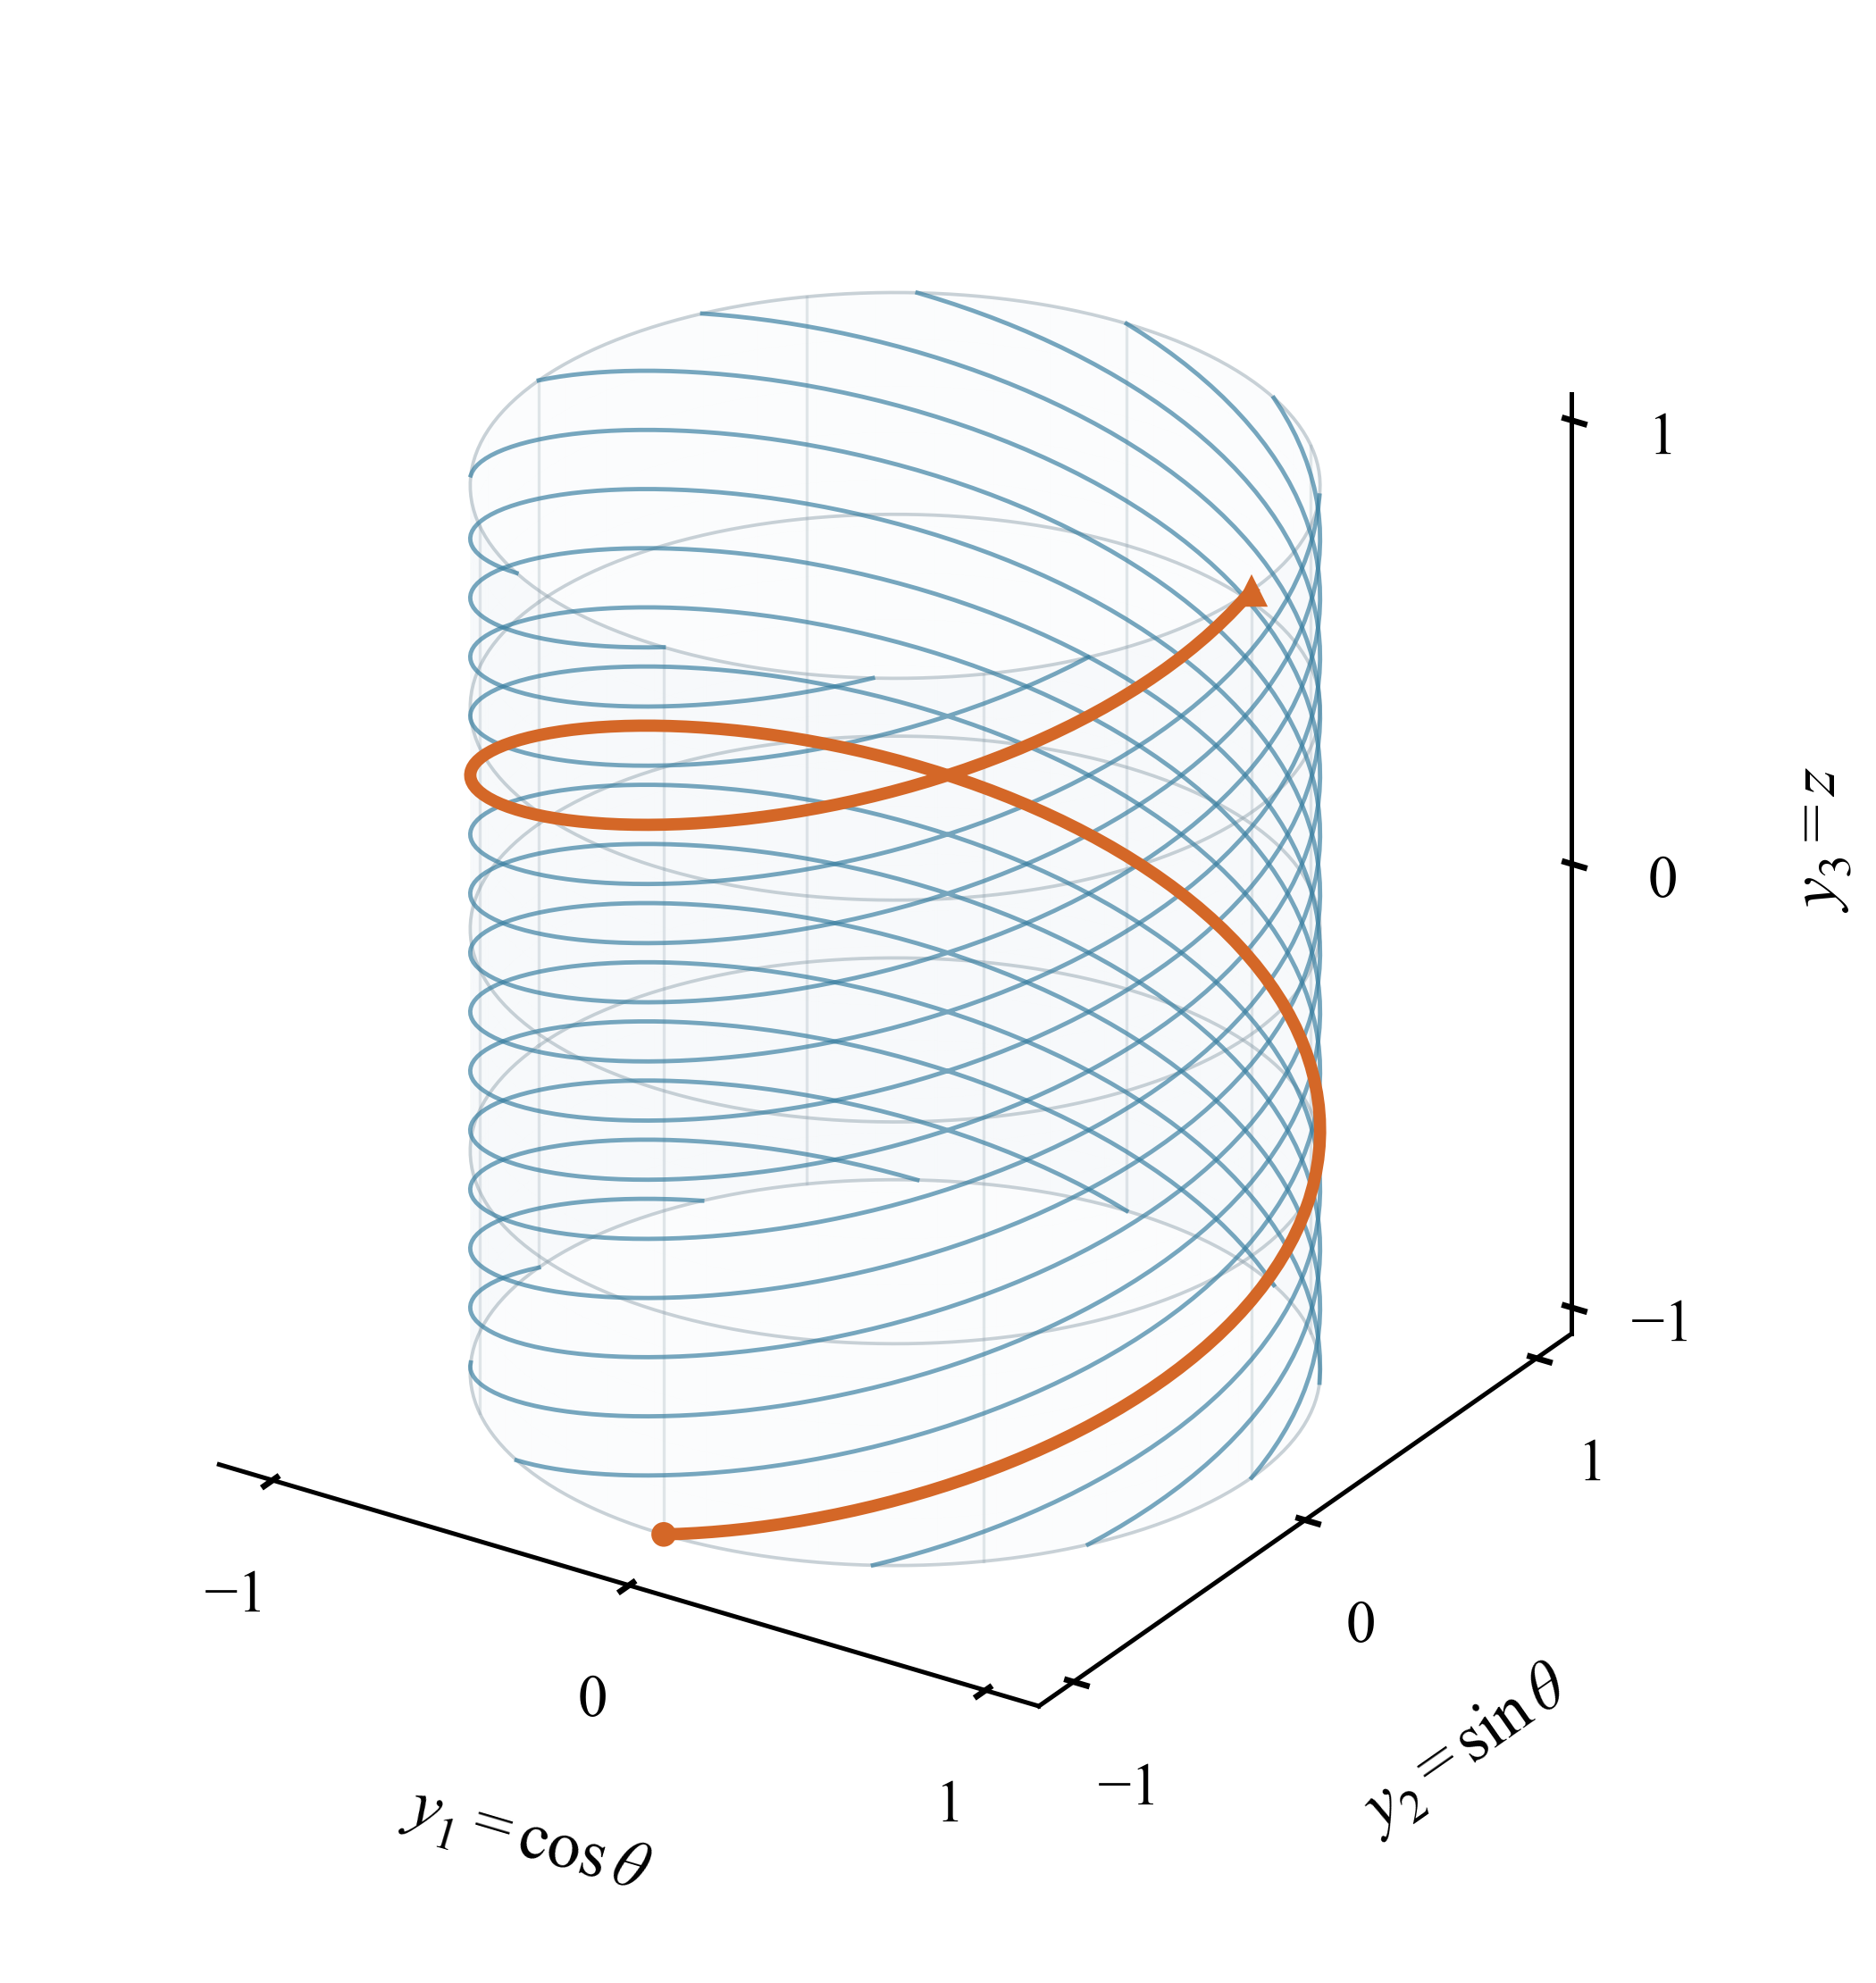

In [3]:
import subprocess
import sys
from IPython.display import Image, display

# A separate process preserves this notebook's plotting backend and style.
paper_script = PROJECT / "notebooks" / "motivation" / "cylinder_paper_figure.py"
result = subprocess.run([sys.executable, str(paper_script)], check=True,
                        capture_output=True, text=True)
print(result.stdout)
display(Image(filename=str(OUT / "cylinder_paper.png"), width=420))

## 2. Learn local groups from measured outputs

Cluster the offline current outputs $y_k$ with $K=16$ means, using the same coordinate scale throughout this illustrative example. No angular intervals or operating-region boundaries are specified. Each group is assigned a rank-two affine plane by centered SVD. Compare its held-out reconstruction error with one global rank-two affine plane. Both planes have the same local dimension, but the atlas has more total parameters and uses a data-dependent assignment.

As a separate prediction diagnostic, fit $\hat y_{k+1}=B^\mathsf T[1,y_k^\mathsf T,u_k^\mathsf T]^\mathsf T$ globally and within each group. This compares one-step prediction in the *same three output coordinates*. Test membership uses only the current measured output; all clustering and fits use training rollouts. Neither the plane error nor this simple regression establishes a DeePC performance result.

In [4]:
N_CHARTS = 16
atlas = KMeans(n_clusters=N_CHARTS, n_init=20, random_state=SEED).fit(Y)
labels = atlas.labels_
labels_test = atlas.predict(Ytest)

def plane_fit(points):
    center = points.mean(axis=0)
    _, _, vt = np.linalg.svd(points - center, full_matrices=False)
    return center, vt[:2].T

def project(points, plane):
    center, basis = plane
    return center + (points - center) @ basis @ basis.T

def features(y, u):
    return np.column_stack([np.ones(len(y)), y, u])

global_plane = plane_fit(Y)
planes = [plane_fit(Y[labels == j]) for j in range(N_CHARTS)]
global_projection = project(Ytest, global_plane)
local_projection = np.empty_like(Ytest)
X = features(Y, U)
Xt = features(Ytest, Utest)
B_global = np.linalg.lstsq(X, Ynext, rcond=None)[0]
B_local = [np.linalg.lstsq(X[labels == j], Ynext[labels == j], rcond=None)[0]
           for j in range(N_CHARTS)]
pred_global = Xt @ B_global
pred_local = np.empty_like(Ytest)
for j in range(N_CHARTS):
    mask = labels_test == j
    local_projection[mask] = project(Ytest[mask], planes[j])
    pred_local[mask] = Xt[mask] @ B_local[j]

def rms_distance(actual, predicted):
    return float(np.sqrt(np.mean(np.sum((actual - predicted)**2, axis=1))))

metrics = {
    "global_plane_rms": rms_distance(Ytest, global_projection),
    "local_planes_rms": rms_distance(Ytest, local_projection),
    "global_prediction_rms": rms_distance(Ynext_test, pred_global),
    "local_prediction_rms": rms_distance(Ynext_test, pred_local),
    "max_cylinder_residual": float(max(
        np.max(np.abs(np.sum(ys[:, :2]**2, axis=1) - 1)) for ys, us in train + test)),
}
print(f"{'Held-out RMS Euclidean error':36s} {'Global':>10s} {'Local':>10s}")
print(f"{'Rank-two affine surface reconstruction':36s} {metrics['global_plane_rms']:10.5f} {metrics['local_planes_rms']:10.5f}")
print(f"{'One-step affine output prediction':36s} {metrics['global_prediction_rms']:10.5f} {metrics['local_prediction_rms']:10.5f}")

Held-out RMS Euclidean error             Global      Local
Rank-two affine surface reconstruction    0.35371    0.02289
One-step affine output prediction       0.08532    0.01843


## 3. Build a graph from transitions that actually occurred

Assign every sample within each offline rollout to its learned group. Add a **directed** edge $i\to j$ only when consecutive samples in the **same** rollout switch from $i$ to $j$; rollout boundaries never create edges. Store an observed sample pair as a witness for each edge.

A representative reference is the observed point nearest each cluster center. Unlike a mean of points around a cylinder, this point lies on the cylinder. Edge cost is Euclidean distance between representatives, a simple geometric heuristic. A shortest graph path provides a sequence of intermediate output references between learned groups.

The graph records observed adjacency. It does not prove that all points within a group can reach every outgoing transition, or that a controller can track the representative sequence. Curved connectors in the figure only display graph connectivity on the known cylinder; they are not simulated trajectories. The plant and graph construction do not use these connectors.

In [5]:
representatives = np.stack([
    Y[labels == j][np.argmin(np.linalg.norm(Y[labels == j] - atlas.cluster_centers_[j], axis=1))]
    for j in range(N_CHARTS)
])
counts = np.zeros((N_CHARTS, N_CHARTS), dtype=int)
witnesses = {}
for ys, us in train:
    labs = atlas.predict(ys)
    for k, (i, j) in enumerate(zip(labs[:-1], labs[1:])):
        if i != j:
            counts[i, j] += 1
            witnesses.setdefault((int(i), int(j)), (ys[k].copy(), us[k].copy(), ys[k+1].copy()))
weights = np.linalg.norm(representatives[:, None] - representatives[None, :], axis=-1)
adjacency = np.where(counts > 0, weights, 0.0)
start_id = int(atlas.predict(embed(-2.4, -0.45)[None])[0])
goal_id = int(atlas.predict(embed(0.55, 0.45)[None])[0])
distances, predecessors = dijkstra(csr_matrix(adjacency), directed=True,
                                   indices=start_id, return_predecessors=True)
if not np.isfinite(distances[goal_id]):
    raise RuntimeError("The selected graph goal is disconnected; collect more exploration data.")
route = [goal_id]
while route[-1] != start_id:
    route.append(int(predecessors[route[-1]]))
route = route[::-1]
route_references = representatives[route]
print("Observed-transition route:", " -> ".join(map(str, route)))
print("Observed edge counts:", [int(counts[i, j]) for i, j in zip(route[:-1], route[1:])])

Observed-transition route: 7 -> 0 -> 12 -> 15 -> 9
Observed edge counts: [14, 16, 24, 20]


## 4. Same measured past, different intended futures

Construct an offline bank of continuations from exactly the same six-output history, with clockwise and counterclockwise motions at several speeds. The inputs for each future motion satisfy the same bounds as the exploration data. Learn two groups by clustering flattened future-output sequences. These are **trajectory groups**, distinct from the spatial groups above: a neighborhood of the current output alone need not distinguish intended motion.

For a requested future reference $r$, score each group by the mismatch between its representative past and the measured history, plus mismatch between its representative future and $r$. Past-only scores tie by construction. Adding the desired reference resolves that ambiguity. References use speeds absent from the offline continuation bank.

This intentionally controlled branching example isolates reference dependence. It does not claim that future motion can be inferred from history alone, and future outputs from a test trajectory are never used for selection: the queried future is a supplied reference. Full contextual DeePC would use the selected data in its predictive optimization.

In [6]:
N_PAST, N_FUTURE = 6, 18
query_theta, query_z = -0.6, 0.0
past = [embed(query_theta - (N_PAST - 1)*H*0.65, query_z)]
for _ in range(N_PAST - 1):
    past.append(step(past[-1], [0.65, -A*past[-1][1]]))
past = np.asarray(past)

def continuation(omega, vertical_speed):
    ys, us = [past[-1].copy()], []
    for _ in range(N_FUTURE):
        u = np.array([omega, vertical_speed - A*ys[-1][1]])
        us.append(u)
        ys.append(step(ys[-1], u))
    return np.asarray(ys), np.asarray(us)

bank = [continuation(sign*speed, sign*0.20)
        for sign in [-1, 1] for speed in np.linspace(0.7, 1.1, 15)]
bank_future = np.stack([ys[1:] for ys, us in bank])
context_groups = KMeans(n_clusters=2, n_init=20, random_state=SEED).fit(
    bank_future.reshape(len(bank), -1))
# Use medoid-like observed representatives, rather than off-surface averages.
context_ids = []
for j in range(2):
    members = np.flatnonzero(context_groups.labels_ == j)
    delta = bank_future[members].reshape(len(members), -1) - context_groups.cluster_centers_[j]
    context_ids.append(int(members[np.argmin(np.linalg.norm(delta, axis=1))]))
context_future = bank_future[context_ids]
context_past = np.repeat(past[None], 2, axis=0)
references = [continuation(0.93, 0.20)[0], continuation(-0.93, -0.20)[0]]
past_scores = np.mean((context_past - past)**2, axis=(1, 2))
selections = []
for reference in references:
    scores = past_scores + np.mean((context_future - reference[1:])**2, axis=(1, 2))
    selections.append(int(np.argmin(scores)))
    print(f"Reference angular direction {np.sign(past[-1, 0]*reference[1, 1] - past[-1, 1]*reference[1, 0]):+.0f}: "
          f"scores {scores.round(5)}; select group {selections[-1]}")
print("History-only scores:", past_scores)

Reference angular direction +1: scores [9.0973e-01 5.1000e-04]; select group 1
Reference angular direction -1: scores [5.1000e-04 9.0973e-01]; select group 0
History-only scores: [0. 0.]


## 5. Paper illustration and a quantitative diagnostic

The overview separates the three motivations. The small translucent patches in panel (a) are learned affine approximations and need not lie exactly on the cylinder. In panel (b), the dashed chord between distant references passes through the cylinder interior: intermediate references describe the available curved geometry. Panel (c) shows actual plant continuations sharing one measured past; solid curves are observed representatives selected using each reference and dashed curves are the supplied references.

The surface itself is drawn from the known embedding for exposition. Clustering, regression, and graph construction receive the measured samples. PNG and PDF exports are written beside this notebook under `figures/`.

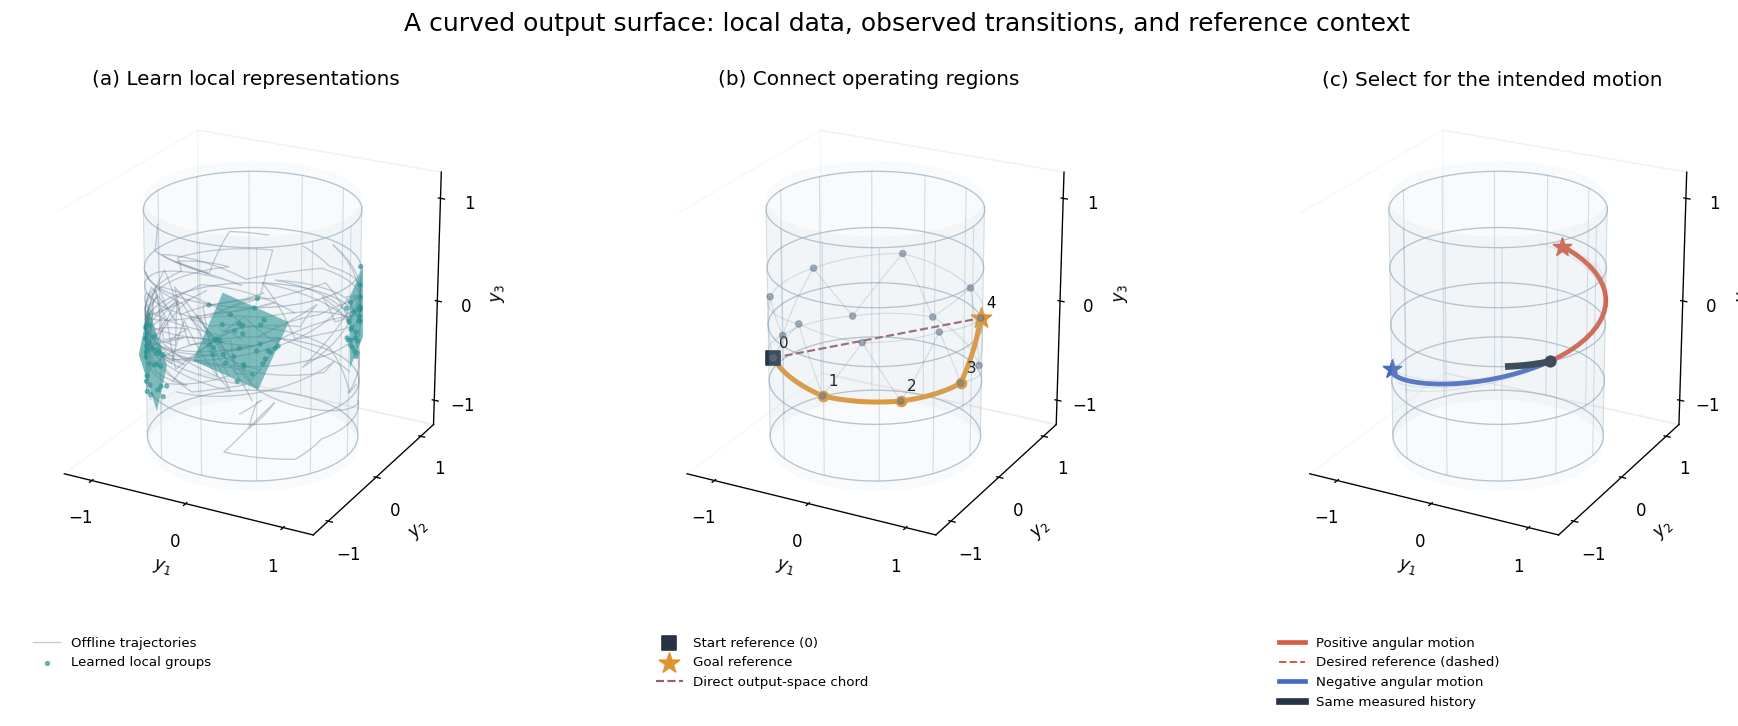

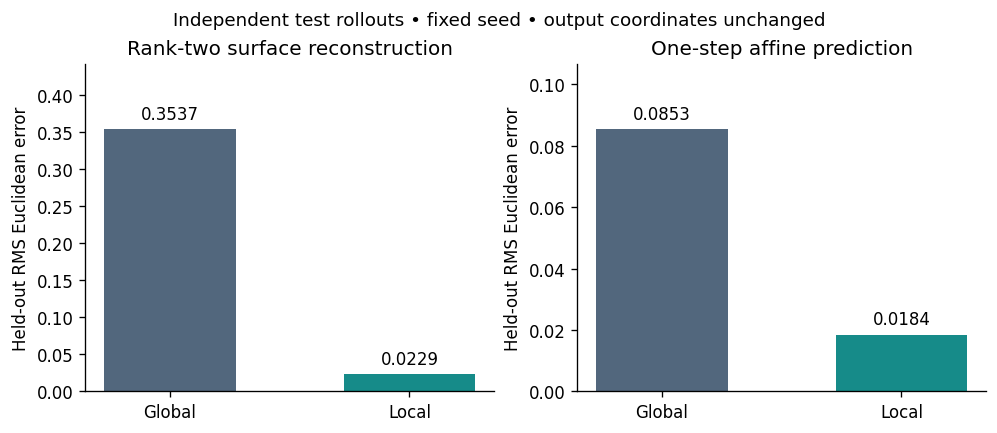

In [7]:
def setup_surface(ax, title):
    theta = np.linspace(-np.pi, np.pi, 90)
    z = np.linspace(-1.2, 1.2, 16)
    tt, zz = np.meshgrid(theta, z)
    ax.plot_surface(np.cos(tt), np.sin(tt), zz, color="#B4C8D5",
                    alpha=0.09, linewidth=0, shade=False)
    for height in np.linspace(-1.1, 1.1, 5):
        ax.plot(np.cos(theta), np.sin(theta), height, color="#8FA5B4", lw=0.8, alpha=0.65)
    for theta0 in np.linspace(-np.pi, np.pi, 12, endpoint=False):
        ax.plot([np.cos(theta0)]*2, [np.sin(theta0)]*2, [-1.1, 1.1],
                color="#8FA5B4", lw=0.65, alpha=0.35)
    ax.set(xlim=(-1.3, 1.3), ylim=(-1.3, 1.3), zlim=(-1.25, 1.25),
           xlabel="$y_1$", ylabel="$y_2$", zlabel="$y_3$", title=title)
    ax.set_xticks([-1, 0, 1]); ax.set_yticks([-1, 0, 1]); ax.set_zticks([-1, 0, 1])
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=23, azim=-62)
    ax.grid(False)
    for axis in [ax.xaxis, ax.yaxis, ax.zaxis]:
        axis.pane.fill = False

def draw_curve(ax, ys, **kwargs):
    return ax.plot(ys[:, 0], ys[:, 1], ys[:, 2], **kwargs)

def graph_connector(a, b):
    # Display-only shortest angular interpolation; not a simulated transition.
    t = np.linspace(0, 1, 30)
    ta, tb = np.arctan2(a[1], a[0]), np.arctan2(b[1], b[0])
    angle = np.arctan2(np.sin(tb-ta), np.cos(tb-ta))
    return embed(ta + t*angle, a[2] + t*(b[2]-a[2]))

fig = plt.figure(figsize=(15.8, 6.3))
axes = [fig.add_subplot(1, 3, j+1, projection="3d") for j in range(3)]
fig.subplots_adjust(left=0.01, right=0.95, bottom=0.25, top=0.87, wspace=0.16)
for ax, title in zip(axes, ["(a) Learn local representations", "(b) Connect operating regions",
                           "(c) Select for the intended motion"]):
    setup_surface(ax, title)
ax = axes[0]
for n, (ys, _) in enumerate(train[:20]):
    draw_curve(ax, ys, color=COLORS["data"], alpha=0.35, lw=0.8,
               label="Offline trajectories" if n == 0 else None)
# Three visible, separated neighborhoods; choices affect presentation only.
shown = np.unique(atlas.predict(embed(np.array([-2.4, -1.1, 0.1]), np.array([-0.4, 0.35, -0.1]))))
for n, j in enumerate(shown):
    center, basis = planes[j]
    aa, bb = np.meshgrid(np.linspace(-0.35, 0.35, 2), np.linspace(-0.32, 0.32, 2))
    patch = center + aa[..., None]*basis[:, 0] + bb[..., None]*basis[:, 1]
    ax.plot_surface(patch[..., 0], patch[..., 1], patch[..., 2],
                    color=COLORS["local"], alpha=0.6, shade=False)
    points = Y[labels == j][::20]
    ax.scatter(*points.T, s=5, color=COLORS["local"], alpha=0.55,
               label="Learned local groups" if n == 0 else None)
ax.legend(loc="upper left", bbox_to_anchor=(0.02, -0.13), fontsize=8, frameon=False)

ax = axes[1]
for i, j in zip(*np.nonzero(counts)):
    draw_curve(ax, graph_connector(representatives[i], representatives[j]),
               color=COLORS["data"], alpha=0.10, lw=0.7)
ax.scatter(*representatives.T, color=COLORS["data"], s=13, alpha=0.5)
for i, j in zip(route[:-1], route[1:]):
    draw_curve(ax, graph_connector(representatives[i], representatives[j]),
               color=COLORS["route"], lw=3)
for order, point in enumerate(route_references):
    ax.scatter(*point, color=COLORS["route"], s=35, depthshade=False)
    ax.text(*(point + np.array([0.04, 0.04, 0.09])), str(order), fontsize=9)
ax.scatter(*route_references[0], marker="s", s=75, color=COLORS["past"], label="Start reference (0)")
ax.scatter(*route_references[-1], marker="*", s=160, color=COLORS["route"], label="Goal reference")
draw_curve(ax, route_references[[0, -1]], ls="--", color="#9B5C65", lw=1.3,
           label="Direct output-space chord")
ax.legend(loc="upper left", bbox_to_anchor=(0.02, -0.13), fontsize=8, frameon=False)

ax = axes[2]
for ys, _ in bank[::3]:
    draw_curve(ax, ys, color=COLORS["data"], alpha=0.13, lw=0.8)
for reference, selected, color, name in zip(references, selections,
        [COLORS["plus"], COLORS["minus"]], ["Positive angular motion", "Negative angular motion"]):
    selected_ys = np.vstack([past[-1], context_future[selected]])
    draw_curve(ax, selected_ys, color=color, lw=2.8, label=name)
    draw_curve(ax, reference, color=color, lw=1.2, ls="--",
               label="Desired reference (dashed)" if selected == selections[0] else None)
    ax.scatter(*reference[-1], color=color, marker="*", s=130)
draw_curve(ax, past, color=COLORS["past"], lw=4, label="Same measured history")
ax.scatter(*past[-1], color=COLORS["past"], s=40, depthshade=False)
ax.legend(loc="upper left", bbox_to_anchor=(0.02, -0.13), fontsize=8, frameon=False)
fig.suptitle("A curved output surface: local data, observed transitions, and reference context", fontsize=15)
for extension in ["png", "pdf"]:
    fig.savefig(OUT / f"cylinder_motivation.{extension}", bbox_inches="tight", pad_inches=0.4)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.5), layout="constrained")
for ax, title, values in zip(axes,
        ["Rank-two surface reconstruction", "One-step affine prediction"],
        [[metrics['global_plane_rms'], metrics['local_planes_rms']],
         [metrics['global_prediction_rms'], metrics['local_prediction_rms']]]):
    bars = ax.bar(["Global", "Local"], values, color=[COLORS["data"], COLORS["local"]], width=0.55)
    ax.bar_label(bars, fmt="%.4f", padding=4)
    ax.set(title=title, ylabel="Held-out RMS Euclidean error", ylim=(0, max(values)*1.25))
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Independent test rollouts • fixed seed • output coordinates unchanged", fontsize=11)
for extension in ["png", "pdf"]:
    fig.savefig(OUT / f"cylinder_diagnostics.{extension}", bbox_inches="tight", pad_inches=0.4)
plt.show()

## 6. Numerical checks and interpretation

The checks below verify the exact invariant, input bounds, held-out fit improvements for this fixed demonstration, graph-edge provenance, on-surface reference points, and reference-dependent selection with identical pasts. The improvement checks are observations of this seeded example, not universal guarantees. All lengths, chart counts, and seeds can be changed in the setup cells.

**Suggested caption.** *Illustrative nonlinear system with outputs on an invariant cylinder. (a) Offline measurements form a curved surface that can be approximated by learned local affine planes. (b) Observed transitions between learned groups define a graph and a sequence of intermediate output references; graph connectors are schematic, and the direct endpoint chord leaves the surface. (c) Identical measured histories admit different future motions, and a supplied reference distinguishes the corresponding trajectory groups. This illustration motivates local prediction, graph-based reference generation, and contextual data selection; it is not a closed-loop DeePC comparison.*

**Scope for the paper.** A two-dimensional invariant output surface is possible even when the measured output has three coordinates. Actual DeePC trajectory matrices combine histories, future outputs, and inputs and usually live in a much larger space. The cylinder should therefore be presented as a geometric illustration of local relevance, not an exact picture of the paper's trajectory subspaces. The graph illustrates intermediate references without establishing that direct goal tracking must fail. No computational-saving claim is measured here.

In [8]:
assert metrics["max_cylinder_residual"] < 1e-12
assert metrics["local_planes_rms"] < metrics["global_plane_rms"]
assert metrics["local_prediction_rms"] < metrics["global_prediction_rms"]
for _, us in train + test + bank:
    assert np.max(np.abs(us[:, 0])) <= 1.2 + 1e-12
    assert np.max(np.abs(us[:, 1])) <= 0.8 + 1e-12
assert np.allclose(np.sum(route_references[:, :2]**2, axis=1), 1)
assert len(route) >= 3
for i, j in zip(route[:-1], route[1:]):
    assert counts[i, j] > 0
    before, u, after = witnesses[i, j]
    assert np.allclose(step(before, u), after)
    assert tuple(atlas.predict(np.stack([before, after]))) == (i, j)
assert np.all(past_scores == 0)
assert selections[0] != selections[1]
metrics.update({"seed": SEED, "charts": N_CHARTS, "train_transitions": len(Y),
                "test_transitions": len(Ytest), "route": route,
                "route_edge_counts": [int(counts[i, j]) for i, j in zip(route[:-1], route[1:])],
                "context_selections": selections})
(OUT / "cylinder_metrics.json").write_text(json.dumps(metrics, indent=2) + "\n")
print("All numerical checks passed.")
print("Figures and metrics:", OUT)

All numerical checks passed.
Figures and metrics: /Users/kumiko/Projects/atlas_deepc_reacher/notebooks/motivation/figures
